In [301]:
import os, re, math, random, sys
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F 
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEVICE)

cuda


In [302]:
BATCH_SIZE = 64
MAX_LEN = 192
LR=1e-3
EPOCHS = 20

## Task 1

In [303]:
def tokenize(s):
    return re.findall(r"[a-z']+|[0-9]+|[^\sa-z0-9]", s.lower())

In [304]:
with open("data/TinyStories-valid.txt", encoding="utf-8") as f:
    text = f.read()
text = text.replace("\u2019", "'").replace("\u2018", "'")
stories = [s.strip() for s in text.split("<|endoftext|>")]
stories = [s for s in stories if s] # drop empty pieces
stories = [s for s in stories if len(tokenize(s)) <= 190] # whole stories only
train_stories = stories[0:8000]
val_stories = stories[8000:8500]
test_stories = stories[8500:9000]

In [305]:
len(train_stories), len(val_stories), len(test_stories)

(8000, 500, 500)

1.1: Number of non-empty stories = 9000

In [306]:
counts = Counter()
for s in train_stories:
    counts.update(tokenize(s))
kept = sorted([t for t, n in counts.items() if n >= 5], key = lambda t: (-counts[t], t))
itos = ["<pad>", "<bos>", "<eos>", "<unk>"] + kept
stoi = {t: i for i, t in enumerate(itos)}
V = len(itos)
assert len(stoi) == len(itos) and all(stoi[itos[k]] == k for k in range(V))
print("V =", V)

V = 4539


In [307]:
def encode(s):
    ids = [stoi.get(t, 3) for t in tokenize(s)][:MAX_LEN-2]
    x = [1] + ids + [2]
    return x + [0] * (MAX_LEN - len(x))

In [308]:
def build(ss):
    X = torch.tensor([encode(s) for s in ss], dtype=torch.long)
    return X[:, :-1].contiguous(), X[:, 1:].contiguous()

In [309]:
tr_inp, tr_tgt = build(train_stories)
va_inp, va_tgt = build(val_stories)
te_inp, te_tgt = build(test_stories)

In [310]:
# calculating number left after 190-token filter:
def calculate_left_out_count(story):
    count = 0
    for s in story:
        ids = [stoi.get(t, 3) for t in tokenize(s)]
        count += max(0, len(ids) - MAX_LEN + 2)
    return count
calculate_left_out_count(train_stories), calculate_left_out_count(val_stories), calculate_left_out_count(test_stories) 

(0, 0, 0)

1.1: So, nothing is left out after the 190-token filter. Size of the three subsets are 8000, 500, 500. V = 4539

In [311]:
def calculate_unk_perc(story):
    unk_count = 0
    tot_count = 0
    for s in story:
        ids = [stoi.get(t, 3) for t in tokenize(s)]
        tot_count += len(ids)
        unk_count += sum([p for p in ids if p == 3])
    return unk_count / tot_count
print(f"val unk: {calculate_unk_perc(val_stories) * 100:.2f}%    test unk: {calculate_unk_perc(test_stories) * 100:.2f}%")

val unk: 2.65%    test unk: 1.62%


1.2: % of word tokens in encoded val set that are unk = 2.64%

In [312]:
print(f"First 15 tokens: {tokenize(train_stories[0])[:15]} \nFirst 16 values of encoded sequence: {encode(train_stories[0])[:16]}")
inp = encode(train_stories[0])
print("Number of true values:", len([x for x in inp if x != 0]))

First 15 tokens: ['spot', '.', 'spot', 'saw', 'the', 'shiny', 'car', 'and', 'said', ',', '"', 'wow', ',', 'kitty', ','] 
First 16 values of encoded sequence: [1, 222, 4, 222, 39, 5, 281, 212, 7, 24, 6, 14, 573, 6, 685, 6]
Number of true values: 84


1.3: <br>
First 15 tokens: ['spot', '.', 'spot', 'saw', 'the', 'shiny', 'car', 'and', 'said', ',', '"', 'wow', ',', 'kitty', ','] <br>
First 16 values of encoded sequence: [1, 222, 4, 222, 39, 5, 281, 212, 7, 24, 6, 14, 573, 6, 685, 6] <br>
Number of true values: 84

In [313]:
def make_loader(inp, tgt, shuffle):
    g = torch.Generator().manual_seed(SEED) if shuffle else None
    return torch.utils.data.DataLoader(torch.utils.data.TensorDataset(inp, tgt), batch_size=BATCH_SIZE, shuffle=shuffle, generator=g, drop_last=False)

In [314]:
train_loader = make_loader(tr_inp, tr_tgt, True)
val_loader = make_loader(va_inp, va_tgt, False)
test_loader = make_loader(te_inp, te_tgt, False)
len(train_loader), len(val_loader), len(test_loader)

(125, 8, 8)

## Task 2

In [315]:
class Attention(nn.Module):
    def __init__(self, D=128, H=4):
        super().__init__()
        self.H, self.d = H, D // H
        self.q = nn.Linear(D, D)
        self.k = nn.Linear(D, D)
        self.v = nn.Linear(D, D)
        self.o = nn.Linear(D, D)
    def forward(self, h, pad_mask, head_mask=None):
        B, T, D = h.shape
        sp = lambda x: x.reshape(B, T, self.H, self.d).transpose(1, 2)
        Q, K, Vv = sp(self.q(h)), sp(self.k(h)), sp(self.v(h))
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.d)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=h.device))
        allowed = causal[None, None] & pad_mask[:, None, None, :]
        A = torch.softmax(scores.masked_fill(~allowed, -float("inf")), dim=-1)
        O = A @ Vv
        if head_mask is not None:
            O = O * head_mask.to(O.device, torch.long).reshape(1, self.H, 1, 1)
        O = O.transpose(1, 2).contiguous().reshape(B, T, D)
        return self.o(O), A

In [316]:
# Checks
torch.manual_seed(SEED)
attn = Attention()
attn.eval()
h = torch.randn(BATCH_SIZE, MAX_LEN-1, 128)
inp, tgt = next(iter(val_loader))
padding_mask = inp != 0
o, a = attn(h, padding_mask)

In [317]:
row_sum = torch.sum(a, dim=-1)
row_sum.shape

torch.Size([64, 4, 191])

In [318]:
torch.max(row_sum), torch.min(row_sum)

(tensor(1.0000, grad_fn=<MaxBackward1>),
 tensor(1.0000, grad_fn=<MinBackward1>))

In [319]:
upper_tri = torch.triu(a, diagonal=1)
torch.max(upper_tri)

tensor(0., grad_fn=<MaxBackward1>)

In [320]:
# tamper test
h[:, 11:, :] = torch.randn(BATCH_SIZE, MAX_LEN-12, 128)
o_new, a_new = attn(h, padding_mask)
new_row_sum = torch.sum(a_new, dim=-1)
new_row_max = torch.max(new_row_sum)
new_row_min = torch.min(new_row_sum)
print(f"Deviation: {(new_row_max - torch.max(row_sum)).item():.7f}, {(new_row_min - torch.min(row_sum)).item():.7f}")
new_upper_tri = torch.triu(a_new, diagonal=1)
new_largest_weight = torch.max(new_upper_tri)
print(f"Deviation: {(new_largest_weight - torch.max(upper_tri)).item():.7f}")

Deviation: 0.0000000, 0.0000001
Deviation: 0.0000000


This is within floating point error

## Task 3

In [321]:
class Block(nn.Module):
    def __init__(self, D = 128):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(D), nn.LayerNorm(D)
        self.att = Attention(D, 4)
        self.drop = nn.Dropout(0.1)
        self.ffn = nn.Sequential(nn.Linear(D, 256),
                                nn.GELU(),
                                nn.Linear(256, D),
                                nn.Dropout(0.1) 
                                )
    def forward(self, h, pm, hm=None):
        a, A = self.att(self.ln1(h), pm, hm)
        h = h + self.drop(a)
        h = h + self.ffn(self.ln2(h))
        return h, A

In [322]:
class LM(nn.Module):
    def __init__(self, V, use_pos=True, D=128):
        super().__init__()
        self.tok = nn.Embedding(V, D)
        if use_pos:
            self.pos = nn.Embedding(MAX_LEN-1, D)
        self.use_pos = use_pos
        self.drop = nn.Dropout(0.1)
        self.blocks = nn.ModuleList([Block(D) for _ in range(2)])
        self.lnf = nn.LayerNorm(D)
        self.out = nn.Linear(D, V)
    def forward(self, inp, head_masks=None):
        pm = inp != 0
        h = self.tok(inp)
        if self.use_pos:
            h = h + self.pos(torch.arange(inp.shape[1], device=inp.device))[None]
        h = self.drop(h)
        As = []
        for i, b in enumerate(self.blocks):
            h, A = b(h, pm, None if head_masks is None else head_masks[i])
            As.append(A)
        return self.out(self.lnf(h)), As

In [323]:
def nparams(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

In [324]:
def evaluate(model, loader, head_masks=None):
    model.eval()
    device=next(model.parameters()).device
    tot, n, corr = 0.0, 0, 0
    with torch.no_grad():
        for inp, tgt in loader:
            inp, tgt = inp.to(device), tgt.to(device)
            logits, _ = model(inp, head_masks)
            fl, ft = logits.reshape(-1, logits.shape[-1]), tgt.reshape(-1)
            tot += F.cross_entropy(fl, ft, ignore_index=0, reduction="sum").item()
            v = ft != 0
            n += v.sum().item()
            corr += ((fl.argmax(-1) == ft) & v).sum().item()
    return tot / n, corr / n

In [325]:
def train_model(model, train_loader, val_loader):
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    device = next(model.parameters()).device
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss(ignore_index=0)
    th, vh = [], []
    for ep in range(1, EPOCHS+1):
        model.train()
        bl = []
        for inp, tgt in train_loader:
            inp, tgt = inp.to(device), tgt.to(device)
            optimizer.zero_grad()
            logits, _ = model(inp)
            loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))
            loss.backward()
            optimizer.step()
            bl.append(loss.item())
        th.append(sum(bl) / len(bl))
        vl, _ = evaluate(model, val_loader)
        vh.append(vl)
        print(f"Epoch {ep}: train {th[-1]:.4f}    val {vh[-1]:.4f}")
    return th, vh

In [326]:
model = LM(V, use_pos=True)
print(nparams(model))

1456187


In [327]:
model.to(DEVICE)
th, vh = train_model(model, train_loader, val_loader)

Epoch 1: train 5.4060    val 4.5907
Epoch 2: train 4.2656    val 4.1533
Epoch 3: train 3.9627    val 3.9657
Epoch 4: train 3.8006    val 3.8397
Epoch 5: train 3.6824    val 3.7467
Epoch 6: train 3.5806    val 3.6605
Epoch 7: train 3.4908    val 3.5842
Epoch 8: train 3.4084    val 3.5139
Epoch 9: train 3.3348    val 3.4671
Epoch 10: train 3.2692    val 3.4091
Epoch 11: train 3.2114    val 3.3623
Epoch 12: train 3.1565    val 3.3228
Epoch 13: train 3.1086    val 3.2921
Epoch 14: train 3.0643    val 3.2605
Epoch 15: train 3.0230    val 3.2330
Epoch 16: train 2.9856    val 3.2055
Epoch 17: train 2.9521    val 3.1862
Epoch 18: train 2.9194    val 3.1661
Epoch 19: train 2.8886    val 3.1490
Epoch 20: train 2.8603    val 3.1366


In [330]:
torch.save({"model": model.state_dict()}, "task3_model.pt")

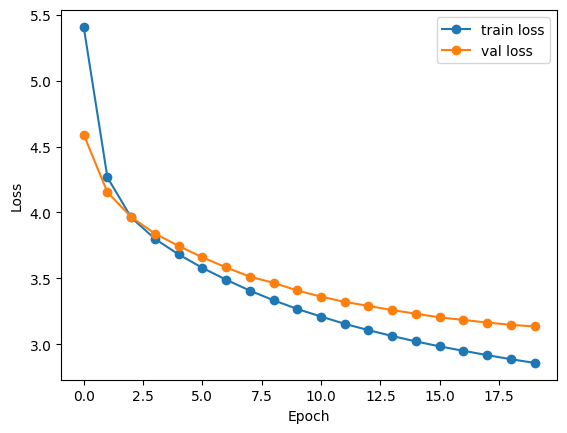

In [331]:
plt.plot(th, marker='o', label="train loss")
plt.plot(vh, marker='o', label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [332]:
t_loss, t_acc = evaluate(model, test_loader)
print(f"Test loss: {t_loss:.4f}     ppl {math.exp(t_loss):.3f}  acc {100 * t_acc:.2f}%")

Test loss: 2.8058     ppl 16.539  acc 41.56%


### Bonus

In [333]:
cp, cv = Counter(), Counter()
for ri, rt in zip(tr_inp.tolist(), tr_tgt.tolist()):
    for a, b in zip(ri, rt):
        if b != 0:
            cp[(a, b)] += 1; cv[a] += 1
nll, nn_ = 0.0, 0
for ri, rt in zip(te_inp.tolist(), te_tgt.tolist()):
    for a, b in zip(ri, rt):
        if b != 0:
            nll += -math.log((cp[(a,b)] + 1) / (cv[a] + V)); nn_ += 1
print(f"Bigram test ppl: {math.exp(nll/nn_):.3f} vs transformer {math.exp(t_loss):.3f}")

Bigram test ppl: 96.470 vs transformer 16.539


## Task 4

In [334]:
def callback_mask(inp, tgt):
    T = inp.shape[1]
    match = tgt[:, :, None] == inp[:, None, :]
    tri = torch.tril(torch.ones(T, T, dtype=torch.bool, device=inp.device))
    tri[:, 0] = False
    match = match & tri[None]
    cb = match.any(-1) & (tgt >= 54)
    return cb, match

## Task 5

In [336]:
@torch.no_grad()
def generate(model, prompt, tau=None):
    model.eval()
    device=next(model.parameters()).device
    seq, ended = list(prompt), False
    while len(seq) < MAX_LEN - 1:
        logits, _ = model(torch.tensor([seq], device=device))
        nl = logits[0, -1, :].clone()
        nl[[0, 1, 3]] = -float("inf")
        if tau is None:
            nid = nl.argmax().item()
        else:
            nid = torch.multinomial(torch.softmax(nl / tau, dim=-1), 1).item()
        seq.append(nid)
        if nid == 2:
            ended = True
            break
    gen = seq[7:]
    if ended:
        gen = gen[:-1]
    return gen, ended

In [339]:
settings = [("greedy", None), ("tau = 0.7", 0.7), ("tau=1.2", 1.2)]
results = {}
for name, tau in settings:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    results[name] = [generate(model, te_inp[i, :7].tolist(), tau) for i in range(50)]

print(f"{'Setting':10s} {'Mean len':>10s} {'EOS %':>9s} {'Distinct-2':>12s}")
for name, tau in settings:
    outs = results[name]
    mean_len = sum(len(g) for g, _ in outs) / len(outs)
    eos_pct = 100 * sum(e for _, e in outs) / len(outs)
    pairs = [p for g, _ in outs for p in zip(g[:-1], g[1:])]
    d2 = len(set(pairs)) / len(pairs) if pairs else "N/A"
    print(f"{name:10s} {mean_len:10.2f} {eos_pct:9.1f} {d2 if d2=='N/A' else format(d2, '12.4f')}")

Setting      Mean len     EOS %   Distinct-2
greedy         128.32     100.0       0.1023
tau = 0.7      141.36     100.0       0.3616
tau=1.2        148.12      90.0       0.7136


In [340]:
dec = lambda ids: " ".join(itos[t] for t in ids)
print("PROMPT 0:", dec(te_inp[0, :7].tolist()))
for name, _ in settings:
    print(f"[{name}]", dec(results[name][0][0]))

PROMPT 0: <bos> once upon a time , there
[greedy] was a little girl named lily . she loved to play outside in the park with her friends . one day , she saw a big tree with a big tree . she wanted to catch it , but it was too hard . lily was sad and didn't know what to do . she wanted to play with her friends . but then , she remembered that she was not to do . lily was sad because she didn't want to play with her friends . lily was sad because she didn't want to play with her friends . lily was sad and didn't want to play with her friends . she learned that sometimes things can be careful when she could not find her .
[tau = 0.7] was a big , scary bear . he lived in a small town who loved to play . one day , he saw a big , a small bird who lived in a tree . he wanted to resist , so he gave it a big hug . the bird was sad and wanted to fly around his house . he tried to reach the tree , but he felt scared . then , he saw a bird ! the bird was so happy that he swam high up and started to

## Task 6

In [343]:
no_pos_model = LM(V, use_pos=False)
print(nparams(no_pos_model))
print("Difference:", nparams(model) - nparams(no_pos_model))

1431739
Difference: 24448


In [344]:
no_pos_model.to(DEVICE)
nth, nvh = train_model(no_pos_model, train_loader, val_loader)

Epoch 1: train 5.1623    val 4.3061
Epoch 2: train 4.0198    val 3.9556
Epoch 3: train 3.7859    val 3.8032
Epoch 4: train 3.6581    val 3.7161
Epoch 5: train 3.5595    val 3.6343
Epoch 6: train 3.4751    val 3.5684
Epoch 7: train 3.4036    val 3.5122
Epoch 8: train 3.3366    val 3.4711
Epoch 9: train 3.2780    val 3.4106
Epoch 10: train 3.2221    val 3.3695
Epoch 11: train 3.1713    val 3.3449
Epoch 12: train 3.1254    val 3.3051
Epoch 13: train 3.0805    val 3.2667
Epoch 14: train 3.0413    val 3.2509
Epoch 15: train 3.0058    val 3.2177
Epoch 16: train 2.9711    val 3.2041
Epoch 17: train 2.9407    val 3.1829
Epoch 18: train 2.9129    val 3.1700
Epoch 19: train 2.8873    val 3.1642
Epoch 20: train 2.8630    val 3.1486


In [345]:
torch.save({"model": no_pos_model.state_dict()}, "task6_model.pt")

In [346]:
def analyse(model, loader, head_masks=None, want_scores=False):
    model.eval()
    device=next(model.parameters()).device
    sc = torch.zeros(2, 4, device=device)
    tot = cbt = oth = 0.0
    n = cbn = on = corr = 0
    with torch.no_grad():
        for inp, tgt in loader:
            inp, tgt = inp.to(device), tgt.to(device)
            logits, As = model(inp, head_masks)
            l = F.cross_entropy(logits.reshape(-1, V), tgt.reshape(-1), ignore_index=0, reduction="none").reshape(tgt.shape)
            cb, match = callback_mask(inp, tgt)
            valid = tgt != 0
            other = valid & ~cb
            tot += l.sum().item(); n += valid.sum().item()
            cbt += l[cb].sum().item(); cbn += cb.sum().item()
            oth += l[other].sum().item(); on += other.sum().item()
            corr += ((logits.argmax(-1) == tgt) & valid).sum().item()
            if want_scores:
                for b in range(2):
                    row = (As[b] * match[:, None].float()).sum(-1)
                    sc[b] += (row * cb[:, None, :].float()).sum((0, 2))
    return dict(loss=tot/n, acc=corr/n, cb_n = cbn, cb_loss = cbt/cbn if cbn else None,
                ot_n=on, ot_loss=oth/on if on else None,
                scores = (sc/cbn).cpu() if (want_scores and cbn) else None)